# 从数据生成到 Transformer



In [8]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)
plt.rcParams["figure.dpi"] = 100
print(torch.__version__)

2.6.0


---
## 1. Linear：从 y = 2x + 1 开始

### 1.1 造数据

真实规律是 $y = 2x + 1$，再加一点噪声。模型只能看到这些点，看不到 2 和 1。

torch.Size([100, 1]) torch.Size([100, 1])


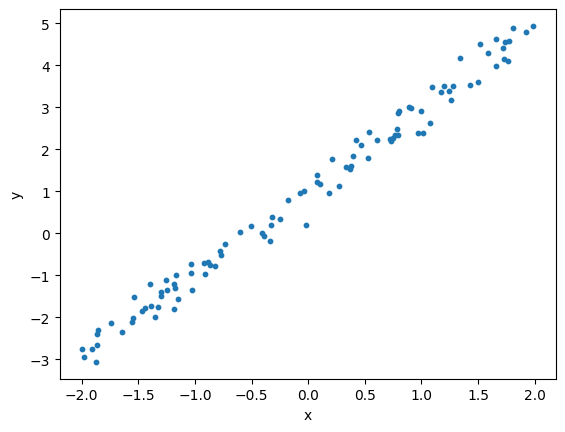

In [9]:
N = 100
x = torch.rand(N, 1) * 4 - 2          # 100 个点，均匀落在 [-2, 2]
#torch.rand用于生成 0 1 之间的随机数
y = 2 * x + 1 + 0.3 * torch.randn(N, 1)

print(x.shape, y.shape)                # (样本数, 特征数)，PyTorch 里几乎所有数据都是这种“批 × 特征”的形状
plt.scatter(x, y, s=10); plt.xlabel("x"); plt.ylabel("y"); plt.show()

### 1.2 Tensor 和自动求导

`torch.Tensor` 用起来和 numpy 数组几乎一样，多了一个能力：**记住自己是怎么算出来的，然后自动求梯度。**

给一个张量打上 `requires_grad=True`，之后用它算出的任何标量调用 `.backward()`，梯度就会出现在 `.grad` 里。

In [10]:
a = torch.tensor(3.0, requires_grad=True)
f = a ** 2 + 2 * a          # f = a² + 2a
f.backward()                # 求 df/da
print(a.grad)               # 2a + 2 = 8

tensor(8.)


### 1.3 手写梯度下降

模型 $\hat y = wx + b$，损失用均方误差 $L = \frac1N\sum(\hat y - y)^2$。

训练就是反复做三件事：算损失，求梯度，沿负梯度方向挪一小步。下面完全手写，不用任何封装。

学到 w = 1.949, b = 0.997  （真值 2, 1）


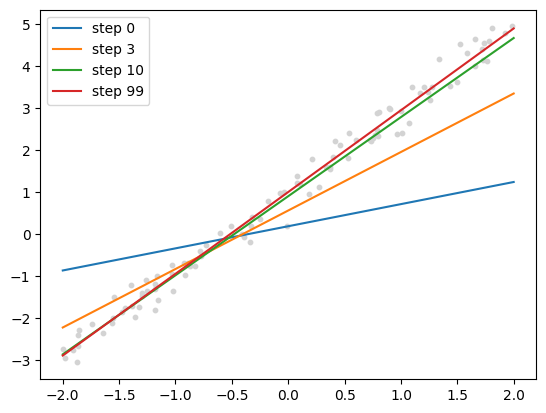

In [11]:
w = torch.zeros(1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
lr = 0.1

snapshots = []
for step in range(100):
    y_hat = w * x + b
    loss = ((y_hat - y) ** 2).mean()

    loss.backward()                  # 算出 w.grad, b.grad
    with torch.no_grad():            # 参数更新这一步不需要被记录进计算图
        w -= lr * w.grad
        b -= lr * b.grad
    w.grad.zero_(); b.grad.zero_()   # 梯度默认会累加，每步要清零

    if step in [0, 3, 10, 99]:
        snapshots.append((step, w.item(), b.item()))

print(f"学到 w = {w.item():.3f}, b = {b.item():.3f}  （真值 2, 1）")

xs = torch.linspace(-2, 2, 100)
plt.scatter(x, y, s=10, c="lightgray")
for step, w_, b_ in snapshots:
    plt.plot(xs, w_ * xs + b_, label=f"step {step}")
plt.legend(); plt.show()

### 1.4 同样的事，用 PyTorch 的标准写法

上面的每一行在 PyTorch 里都有对应的封装：

- 参数 `w, b` → `nn.Linear(1, 1)`，它内部就存着一个 weight 和一个 bias
- 手动更新 → `torch.optim.SGD` / `Adam`，`opt.step()` 一行完成
- 清零梯度 → `opt.zero_grad()`

所有模型都写成 `nn.Module` 的子类（或者用 `nn.Sequential` 直接串起来），之后每一节的训练循环都长得一模一样，所以写一个 `fit` 函数复用到最后。

In [12]:
#这里我们把训练循环包装成函数
#用法示例：fit(nn.Linear(1, 1), full_batch(x, y), F.mse_loss, steps=500, lr=0.05)
# fit(big_mlp(), full_batch(Xtr, Ytr), F.cross_entropy, steps=2000, reg=l2)
# fit(cnn, mini_batch(Xi_tr, Yi_tr, 100), F.cross_entropy, steps=1800, lr=3e-3)
def fit(model, get_batch, loss_fn, steps, lr=1e-3, reg=None, log_every=None):
    # get_batch() 每次返回一批 (x, y)；reg(model) 可选，返回加到 loss 上的正则项
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    model.train()
    for step in range(steps):
        xb, yb = get_batch()
        loss = loss_fn(model(xb), yb)
        if reg is not None:
            loss = loss + reg(model)
        opt.zero_grad()
        loss.backward()
        opt.step()
        if log_every and step % log_every == 0:
            print(f"step {step:5d}  loss {loss.item():.4f}")
    model.eval()
    return model

def full_batch(X, Y):                  # 小数据集：每步都用全部数据
    return lambda: (X, Y)

def mini_batch(X, Y, bs):              # 大数据集：每步随机取 bs 个
    def get():
        i = torch.randint(0, len(X), (bs,))
        return X[i], Y[i]
    return get

In [13]:
lin = nn.Linear(1, 1)
fit(lin, full_batch(x, y), F.mse_loss, steps=500, lr=0.05)
print(lin.weight.item(), lin.bias.item())

1.9485609531402588 0.9967774748802185


**可以试试**：把 `lr` 调到 1.0 或 0.001，看会发生什么。

---
## 2. MLP

### 2.1 线性模型的失败

把真实规律换成 $y = \sin x$。线性模型无论怎么训练，输出都只能是一条直线。

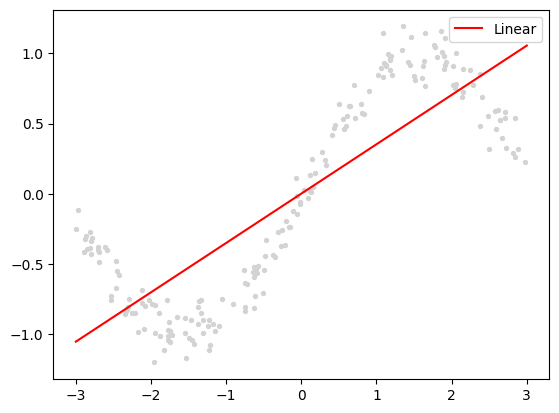

In [14]:
torch.manual_seed(0)
x = torch.rand(200, 1) * 6 - 3
y = torch.sin(x) + 0.1 * torch.randn(200, 1)
xs = torch.linspace(-3, 3, 300).unsqueeze(1)

lin = fit(nn.Linear(1, 1), full_batch(x, y), F.mse_loss, steps=1000, lr=0.05)
with torch.no_grad():
    plt.scatter(x, y, s=8, c="lightgray"); plt.plot(xs, lin(xs), "r", label="Linear"); plt.legend(); plt.show()

### 2.2 叠两层线性也没用

直觉上可以把线性层叠起来让模型“更强”。但 $W_2(W_1 x + b_1) + b_2 = (W_2W_1)x + (W_2 b_1 + b_2)$，两层合起来仍然是一个线性变换。叠多少层都一样，下面数值验证一下。

In [15]:
two = nn.Sequential(nn.Linear(1, 16), nn.Linear(16, 1))
W1, b1 = two[0].weight, two[0].bias
W2, b2 = two[1].weight, two[1].bias
W, b = W2 @ W1, W2 @ b1 + b2            # 合并成一层

with torch.no_grad():
    print(torch.allclose(two(xs), xs @ W.T + b, atol=1e-6))   # True：完全等价
#torch.allclose用于判断两个张量是否接近

True


### 2.3 加一个非线性

问题出在“线性接线性”。在两层之间插一个逐元素的非线性函数，合并就不成立了。最常用的是 ReLU：$\text{ReLU}(z) = \max(0, z)$。

先用只有 8 个隐藏单元的小网络，看看它到底是怎么拟合曲线的。

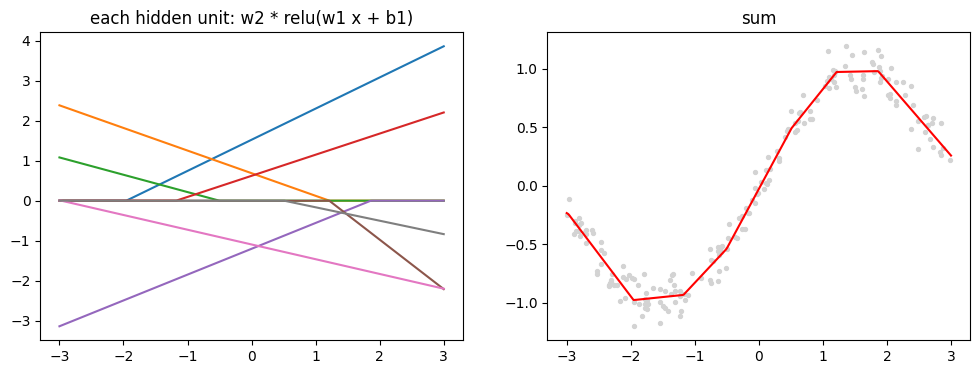

In [16]:
torch.manual_seed(1)
mlp = nn.Sequential(nn.Linear(1, 8), nn.ReLU(), nn.Linear(8, 1))
fit(mlp, full_batch(x, y), F.mse_loss, steps=3000, lr=1e-2)

with torch.no_grad():
    h = torch.relu(mlp[0](xs))                    # (300, 8)：每个隐藏单元的输出
    parts = h * mlp[2].weight                     # 乘上第二层的权重
    total = parts.sum(1) + mlp[2].bias

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for j in range(8):
    ax[0].plot(xs, parts[:, j])
ax[0].set_title("each hidden unit: w2 * relu(w1 x + b1)")
ax[1].scatter(x, y, s=8, c="lightgray"); ax[1].plot(xs, total, "r"); ax[1].set_title("sum")
plt.show()

左图每条线都是一个“折一次的直线”，右图是它们加起来。**MLP 就是用一堆折线拼出任意形状**，隐藏单元越多，能拼得越细。

### 2.4 分类：输出变成概率

换成二维平面上的二分类。数据是两个交错的月牙（moons）。

分类时网络最后输出 2 个数（logits），经过 softmax 变成两类的概率，损失用交叉熵 `F.cross_entropy`。

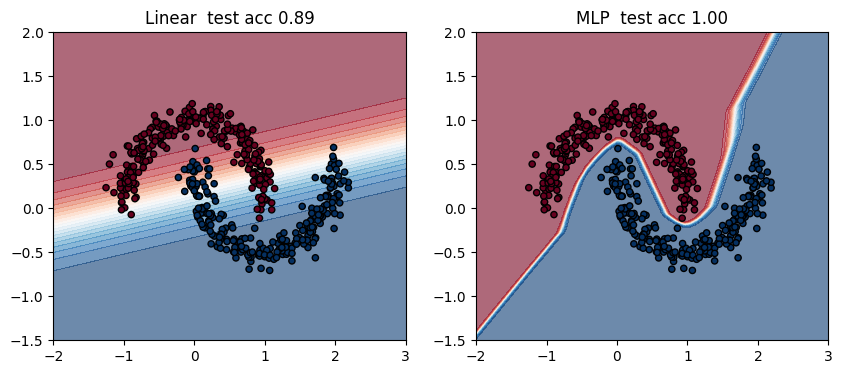

In [17]:
def make_moons(n, noise=0.25, seed=0):
    g = torch.Generator().manual_seed(seed)
    t = torch.rand(n, generator=g) * math.pi
    label = (torch.rand(n, generator=g) < 0.5).long()
    X = torch.stack([torch.cos(t), torch.sin(t)], 1)                      # 上面的月牙
    X[label == 1] = torch.stack([1 - torch.cos(t), 0.5 - torch.sin(t)], 1)[label == 1]  # 下面的月牙
    return X + noise * torch.randn(n, 2, generator=g), label

gx, gy = torch.meshgrid(torch.linspace(-2, 3, 200), torch.linspace(-1.5, 2, 200), indexing="xy")
grid = torch.stack([gx.ravel(), gy.ravel()], 1)

def plot_boundary(model, X, Y, ax, title=""):
    with torch.no_grad():
        p = model(grid).softmax(1)[:, 1].reshape(200, 200)
    ax.contourf(gx, gy, p, levels=20, cmap="RdBu", alpha=0.6)
    ax.scatter(X[:, 0], X[:, 1], c=Y, cmap="RdBu", edgecolors="k", s=20)
    ax.set_title(title)

def acc(model, X, Y):
    with torch.no_grad():
        return (model(X).argmax(1) == Y).float().mean().item()

Xm, Ym = make_moons(500, noise=0.1)
Xm_test, Ym_test = make_moons(2000, noise=0.1, seed=1)

torch.manual_seed(0)
lin = fit(nn.Linear(2, 2), full_batch(Xm, Ym), F.cross_entropy, steps=1000, lr=1e-2)
mlp = fit(nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 2)),
          full_batch(Xm, Ym), F.cross_entropy, steps=1000, lr=1e-2)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
plot_boundary(lin, Xm, Ym, ax[0], f"Linear  test acc {acc(lin, Xm_test, Ym_test):.2f}")
plot_boundary(mlp, Xm, Ym, ax[1], f"MLP  test acc {acc(mlp, Xm_test, Ym_test):.2f}")
plt.show()

---
## 3. 过拟合、L2 正则、Dropout

### 3.1 让 MLP 犯错

MLP 能拼出任意形状，这也是它的问题：数据里的噪声它也会拼进去。

还是月牙生成器，但只采 100 个点，并且**随机翻转 15% 的标签**（模拟标注错误）。测试集是 2000 个干净的点。

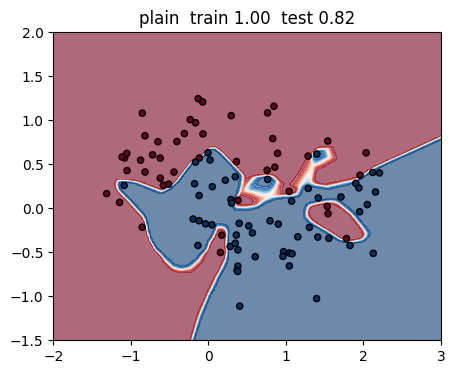

In [18]:
Xtr, Ytr = make_moons(100, noise=0.25, seed=0)
g = torch.Generator().manual_seed(1)
flip = torch.rand(100, generator=g) < 0.15
Ytr[flip] = 1 - Ytr[flip]
Xte, Yte = make_moons(2000, noise=0.25, seed=1)

def big_mlp(p_drop=0.0):
    layers, d = [], 2
    for _ in range(2):
        layers += [nn.Linear(d, 256), nn.ReLU()]
        if p_drop > 0:
            layers.append(nn.Dropout(p_drop))
        d = 256
    return nn.Sequential(*layers, nn.Linear(256, 2))

torch.manual_seed(0)
plain = fit(big_mlp(), full_batch(Xtr, Ytr), F.cross_entropy, steps=2000)

fig, ax = plt.subplots(figsize=(5, 4))
plot_boundary(plain, Xtr, Ytr, ax, f"plain  train {acc(plain, Xtr, Ytr):.2f}  test {acc(plain, Xte, Yte):.2f}")
plt.show()

训练准确率接近 100%，决策边界为了照顾每一个翻错的点，长出很多小岛。这些小岛在测试集上全是错的。这就是**过拟合**：模型记住了训练数据，包括其中的噪声。

两种思路去压住它，都在同一份数据上试。

### 3.2 L2 正则：控制权重大小

边界要拐出小岛，需要很陡的函数，陡的函数需要大的权重。那就在损失里加一项惩罚权重大小：

$$L = L_{\text{data}} + \lambda \sum w^2$$

模型现在要在“拟合数据”和“保持权重小”之间折中，翻错的那几个点不值得为它们把权重变大。

In [19]:
def l2(model, lam=1e-2):
    return lam * sum((p ** 2).sum() for name, p in model.named_parameters() if "weight" in name)

torch.manual_seed(0)
l2_model = fit(big_mlp(), full_batch(Xtr, Ytr), F.cross_entropy, steps=2000, reg=l2)

（PyTorch 里更常见的写法是 `torch.optim.AdamW(..., weight_decay=...)`，作用相同，这里手写是为了看清楚它就是 loss 上多加的一项。）

### 3.3 Dropout：训练时随机关掉一部分神经元

训练的每一步，以概率 $p$ 随机把隐藏单元置零。任何一个特征都可能突然消失，网络没法依赖某几个特定的神经元去“专门记住”某个翻错的点，只能学那些很多神经元都认同的、稳定的模式。

测试时不再丢弃，用全部神经元（PyTorch 内部会自动做缩放，保证期望一致）。所以 Dropout 的模型有两种模式：

- `model.train()`：Dropout 生效
- `model.eval()`：Dropout 关闭

`fit` 里训练前调了 `train()`，结束后调了 `eval()`，就是为了这个。

In [20]:
torch.manual_seed(0)
drop_model = fit(big_mlp(p_drop=0.7), full_batch(Xtr, Ytr), F.cross_entropy, steps=2000)

# 看一眼两种模式的区别：同一个输入，train 模式每次输出都不同
drop_model.train()
print(drop_model(Xtr[:1]), drop_model(Xtr[:1]))
drop_model.eval()
print(drop_model(Xtr[:1]), drop_model(Xtr[:1]))

tensor([[-0.8463,  1.6487]], grad_fn=<AddmmBackward0>) tensor([[ 0.2855, -0.4897]], grad_fn=<AddmmBackward0>)
tensor([[-0.1003,  0.1689]], grad_fn=<AddmmBackward0>) tensor([[-0.1003,  0.1689]], grad_fn=<AddmmBackward0>)


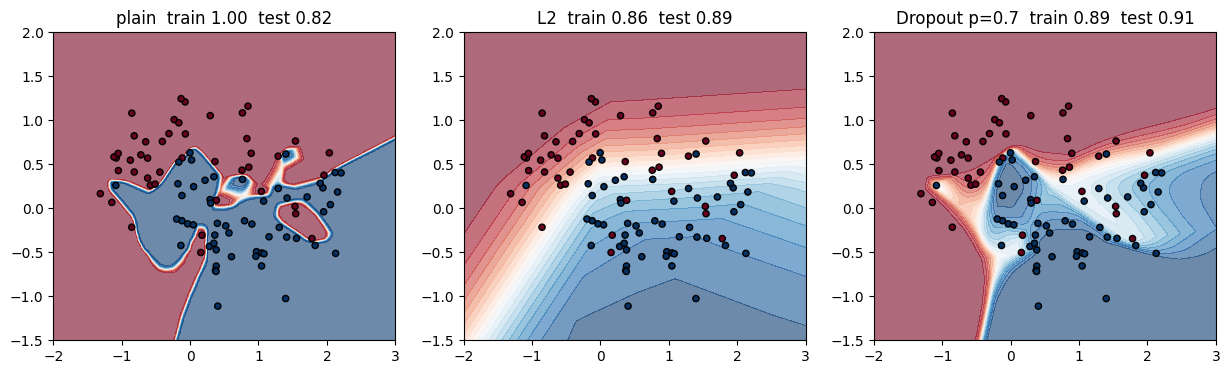

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (name, m) in zip(ax, [("plain", plain), ("L2", l2_model), ("Dropout p=0.7", drop_model)]):
    plot_boundary(m, Xtr, Ytr, a, f"{name}  train {acc(m, Xtr, Ytr):.2f}  test {acc(m, Xte, Yte):.2f}")
plt.show()

两种方法都让训练准确率下降、测试准确率上升：放弃拟合那些翻错的点，换来更好的泛化。

**可以试试**：改 `lam` 和 `p_drop`。太小没效果，太大会连正确的结构都学不出来（欠拟合）。

---
## 4. CNN：图案可以出现在任何位置

### 4.1 造数据

16×16 的灰度图，加噪声，里面放一个 3×3 的图案：“十”是第 0 类，“×”是第 1 类。

关键设计：**训练集的图案只出现在左半边，测试集分两份，一份在左半边，一份在右半边。**

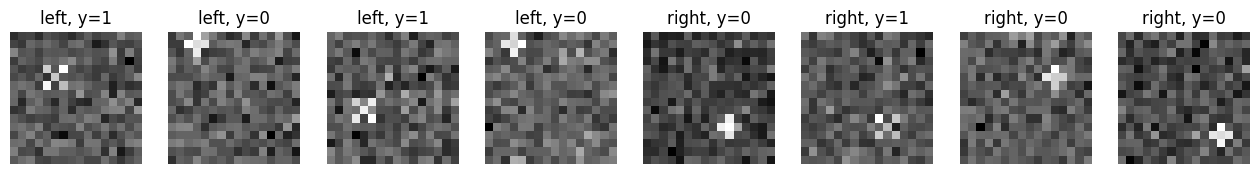

In [22]:
S = 16
PLUS  = torch.tensor([[0, 1, 0], [1, 1, 1], [0, 1, 0]], dtype=torch.float)
CROSS = torch.tensor([[1, 0, 1], [0, 1, 0], [1, 0, 1]], dtype=torch.float)

def make_images(n, side, seed):
    g = torch.Generator().manual_seed(seed)
    X = 0.2 * torch.randn(n, 1, S, S, generator=g)       # (样本, 通道, 高, 宽)
    Y = torch.randint(0, 2, (n,), generator=g)
    rows = torch.randint(0, S - 2, (n,), generator=g)
    lo, hi = (0, S // 2 - 2) if side == "left" else (S // 2, S - 2)
    cols = torch.randint(lo, hi, (n,), generator=g)
    for i in range(n):
        X[i, 0, rows[i]:rows[i] + 3, cols[i]:cols[i] + 3] += PLUS if Y[i] == 0 else CROSS
    return X, Y

Xi_tr, Yi_tr = make_images(6000, "left", seed=0)
Xi_L,  Yi_L  = make_images(1000, "left", seed=1)
Xi_R,  Yi_R  = make_images(1000, "right", seed=2)

fig, ax = plt.subplots(1, 8, figsize=(16, 2))
for k in range(4):
    ax[k].imshow(Xi_L[k, 0], cmap="gray"); ax[k].set_title(f"left, y={Yi_L[k].item()}")
    ax[k + 4].imshow(Xi_R[k, 0], cmap="gray"); ax[k + 4].set_title(f"right, y={Yi_R[k].item()}")
for a in ax: a.axis("off")
plt.show()

### 4.2 MLP 的失败

把图拉平成 256 维向量喂给 MLP。

In [23]:
def n_params(m): return sum(p.numel() for p in m.parameters())

torch.manual_seed(0)
mlp_img = nn.Sequential(nn.Flatten(), nn.Linear(S * S, 256), nn.ReLU(), nn.Linear(256, 2))
fit(mlp_img, mini_batch(Xi_tr, Yi_tr, 100), F.cross_entropy, steps=1800, lr=3e-3)
print(f"MLP  params {n_params(mlp_img)}  left {acc(mlp_img, Xi_L, Yi_L):.3f}  right {acc(mlp_img, Xi_R, Yi_R):.3f}")

MLP  params 66306  left 0.911  right 0.466


左半边还行，右半边是 0.5，相当于随机猜测。

原因在于 MLP 的第一层给每个像素位置一套独立的权重。“左上角有个十字”和“右下角有个十字”对它来说是两件毫不相干的事，右半边的像素权重在训练中从没见过图案，自然什么都没学到。

但我们知道，识别十字只需要看一个 3×3 的局部，而且在哪里看都应该用同一个判断标准。把这两句话直接写成结构：

- 只看局部：用一个 3×3 的小权重矩阵（卷积核）
- 处处同一标准：让这个卷积核滑过整张图，每个位置共享同一组权重

滑完得到一张“响应图”（feature map），某处出现了卷积核在找的图案，那里的响应就高。最后对整张响应图取最大值（global max pooling），表示“图里任意位置有没有这个图案”。这就是卷积神经网络。

In [24]:
torch.manual_seed(0)
cnn = nn.Sequential(
    nn.Conv2d(1, 8, kernel_size=3),   # 8 个 3×3 卷积核
    nn.ReLU(),
    nn.AdaptiveMaxPool2d(1),          # 每张 feature map 取全局最大值 → 8 个数
    nn.Flatten(),
    nn.Linear(8, 2),
)
fit(cnn, mini_batch(Xi_tr, Yi_tr, 100), F.cross_entropy, steps=1800, lr=3e-3)
print(f"CNN  params {n_params(cnn)}  left {acc(cnn, Xi_L, Yi_L):.3f}  right {acc(cnn, Xi_R, Yi_R):.3f}")

CNN  params 98  left 1.000  right 0.991


参数量少了几百倍，右半边从没见过的位置也几乎全对。

MLP 和 CNN 都能表示这个函数，区别在于 CNN 把“局部 + 平移不变”这个关于数据的假设直接写进了结构。选网络结构，本质上是在选归纳偏置。

### 4.3 把 CNN 做大：和 MLP 参数量相当

上面的 CNN 只用 98 个参数就够了，因为任务太简单，只有一个 3×3 的图案。

这一节换一个难一点的任务。MLP 还是用 4.2 那个，CNN 则做大到和它**差不多的参数量**（6~7 万），直接比：

- 16×16 的图（和 4.1 一样大）里写一个 0–9 的数字（5×7 点阵字体），位置随机，加噪声
- 再贴 3 块从别的数字上切下来的 3×3 笔画碎片当干扰
- 10 分类，随机猜的准确率是 10%
- 训练集和测试集里，数字都可能出现在**全图任意位置**，所以 MLP 训练时每个位置都见过

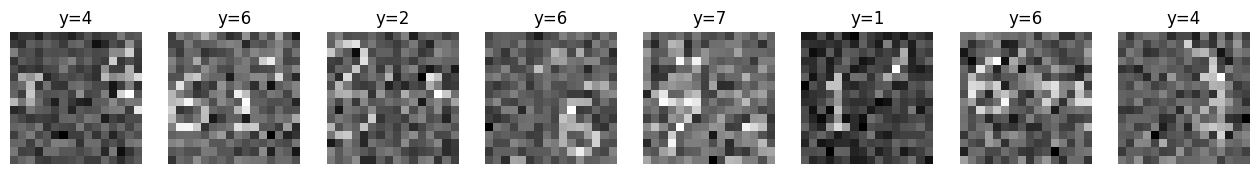

In [25]:
FONT = """
01110 00100 01110 11111 00010 11111 00110 11111 01110 01110
10001 01100 10001 00010 00110 10000 01000 00001 10001 10001
10011 00100 00001 00100 01010 11110 10000 00010 10001 10001
10101 00100 00010 00010 10010 00001 11110 00100 01110 01111
11001 00100 00100 00001 11111 00001 10001 01000 10001 00001
10001 00100 01000 10001 00010 10001 10001 01000 10001 00010
01110 01110 11111 01110 00010 01110 01110 01000 01110 01100
"""                                    # 每一列是一个数字的 5×7 点阵，从左到右依次是 0~9
font_rows = [r.split() for r in FONT.strip().splitlines()]
GLYPHS = torch.tensor([[[int(ch) for ch in font_rows[r][d]] for r in range(7)] for d in range(10)], dtype=torch.float)  # (10, 7, 5)

def make_digits(n, seed, n_frag=3):
    g = torch.Generator().manual_seed(seed)
    rnd = lambda hi: torch.randint(0, hi, (1,), generator=g).item()    # [0, hi) 里的随机整数
    X = 0.3 * torch.randn(n, 1, S, S, generator=g)
    Y = torch.randint(0, 10, (n,), generator=g)
    for i in range(n):
        r, c = rnd(S - 7 + 1), rnd(S - 5 + 1)                          # 数字放在全图任意位置
        X[i, 0, r:r + 7, c:c + 5] += GLYPHS[Y[i]]
        for _ in range(n_frag):                                        # 干扰：从随机某个数字上切一块 3×3 的笔画
            d, fr, fc = rnd(10), rnd(5), rnd(3)
            r, c = rnd(S - 3 + 1), rnd(S - 3 + 1)
            X[i, 0, r:r + 3, c:c + 3] += GLYPHS[d, fr:fr + 3, fc:fc + 3]
    return X, Y

Xd_tr, Yd_tr = make_digits(20000, seed=0)
Xd_te, Yd_te = make_digits(2000, seed=1)

fig, ax = plt.subplots(1, 8, figsize=(16, 2))
for k in range(8):
    ax[k].imshow(Xd_te[k, 0], cmap="gray"); ax[k].set_title(f"y={Yd_te[k].item()}"); ax[k].axis("off")
plt.show()

先把 4.2 的两个模型原样搬过来，只把输出从 2 类改成 10 类：

- **MLP**：和 4.2 完全一样，拉平成 256 维，一个 256 单元的隐藏层。参数 68,362，比 4.2 的 66,306 多出来的部分全在输出层
- **小 CNN**：一层 8 个 3×3 卷积核加全局最大值，参数 170

In [26]:
def digit_mlp(hidden=256):                     # 结构和 4.2 的 MLP 一样，hidden=256 就是 4.2 那个
    return nn.Sequential(nn.Flatten(), nn.Linear(S * S, hidden), nn.ReLU(), nn.Linear(hidden, 10))

def report(name, m):
    tr, te = acc(m, Xd_tr[:2000], Yd_tr[:2000]), acc(m, Xd_te, Yd_te)    # 训练准确率用前 2000 张估计，省时间
    print(f"{name:9s} params {n_params(m):9,d}  train {tr:.3f}  test {te:.3f}")
    return tr, te

torch.manual_seed(0)
mlp_d = fit(digit_mlp(256), mini_batch(Xd_tr, Yd_tr, 128), F.cross_entropy, steps=800, lr=3e-3)
torch.manual_seed(0)
cnn_tiny = fit(nn.Sequential(nn.Conv2d(1, 8, 3), nn.ReLU(), nn.AdaptiveMaxPool2d(1), nn.Flatten(), nn.Linear(8, 10)),
               mini_batch(Xd_tr, Yd_tr, 128), F.cross_entropy, steps=800, lr=3e-3)

report("MLP", mlp_d)
report("tiny CNN", cnn_tiny);

MLP       params    68,362  train 0.832  test 0.431
tiny CNN  params       170  train 0.403  test 0.417


两个都不行，但问题出在不同的地方：

- **MLP 在背题**：训练集 0.83，测试集只有 0.43。同一个“3”往右挪一个像素，在 MLP 看来就是另一个 256 维输入，每个位置都得单独学。10 个数字 × 120 个位置，平均每种组合只有十几张训练图，还各带不同的噪声和干扰，它只能把见过的图背下来，换一张就认不出了。
- **小 CNN 是能力不够**：训练集也只有 0.40，连训练数据都拟合不了（欠拟合）。8 个 3×3 的窗口只能回答“图里有没有某一小段笔画”。横、竖、拐角每个数字都有，干扰碎片里也有，只靠这个分不出 10 个数字。（不过它只有 170 个参数，测试准确率 0.42 已经和 MLP 差不多了。）

小 CNN 的问题可以通过把 CNN 做大来解决，有两个方向：

- **加深**：叠 4 层卷积，第 2、3 层后面各接一个 `MaxPool2d(2)`，把图缩小一半。图缩小以后，下一层的 3×3 窗口对应原图里更大的一块：第一层看到 3×3（一小段笔画），第二层 5×5（几段笔画的组合），第三层 10×10，已经能盖住整个数字（7×5）。这个范围叫**感受野**。
- **加宽**：每层多用几个卷积核，同时找更多种图案。下面用宽度 `w` 控制，四层的通道数是 `w, 2w, 4w, 4w`。

最后仍然接 4.2 的全局最大值，所以“数字在哪都一样”这条假设没有变。取 `w=16`，参数 60,874，和 MLP 差不多。在 CPU 上训练大约 20 秒。

MLP       params    68,362  train 0.832  test 0.431
tiny CNN  params       170  train 0.403  test 0.417
big CNN   params    60,874  train 0.993  test 0.982


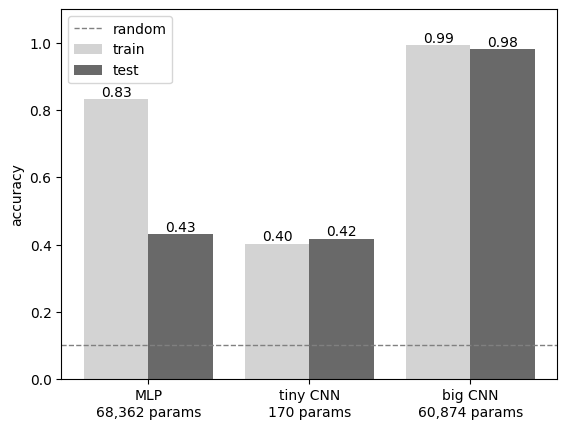

In [27]:
def scaled_cnn(w):
    return nn.Sequential(
        nn.Conv2d(1, w, 3, padding=1), nn.ReLU(),                             # 感受野 3×3：一小段笔画
        nn.Conv2d(w, 2 * w, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),        # 感受野 5×5：笔画的组合      16→8
        nn.Conv2d(2 * w, 4 * w, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 感受野 10×10：整个数字      8→4
        nn.Conv2d(4 * w, 4 * w, 3, padding=1), nn.ReLU(),                     # 感受野覆盖全图
        nn.AdaptiveMaxPool2d(1), nn.Flatten(),                                # 和 4.2 一样：全局最大值
        nn.Linear(4 * w, 10),
    )

torch.manual_seed(0)
cnn_big = fit(scaled_cnn(16), mini_batch(Xd_tr, Yd_tr, 128), F.cross_entropy, steps=800, lr=3e-3)

names, models = ["MLP", "tiny CNN", "big CNN"], [mlp_d, cnn_tiny, cnn_big]
res = [report(n, m) for n, m in zip(names, models)]

pos = torch.arange(3).float()
plt.bar_label(plt.bar(pos - 0.2, [r[0] for r in res], 0.4, color="lightgray", label="train"), fmt="%.2f")
plt.bar_label(plt.bar(pos + 0.2, [r[1] for r in res], 0.4, color="dimgray", label="test"), fmt="%.2f")
plt.axhline(0.1, ls="--", c="gray", lw=1, label="random")
plt.xticks(pos, [f"{n}\n{n_params(m):,} params" for n, m in zip(names, models)])
plt.ylabel("accuracy"); plt.ylim(0, 1.1); plt.legend(loc="upper left"); plt.show()

参数量差不多，测试准确率 0.43 对 0.98。

差别在于参数花在了哪里。MLP 的 68,362 个参数里，有 65,536 个是第一层“每个像素连到每个隐藏单元”的权重。同一段笔画可能出现在 100 多个位置，每个位置都要在这些权重里单独学一遍。CNN 的参数全部是卷积核，一套卷积核在整张图上共用，学会一次就能在任何位置用，省下来的参数可以拿去加层、加通道。

取测试集前 8 张图，看看两个模型各自认成了什么（红色带 ✗ 的是认错的）：

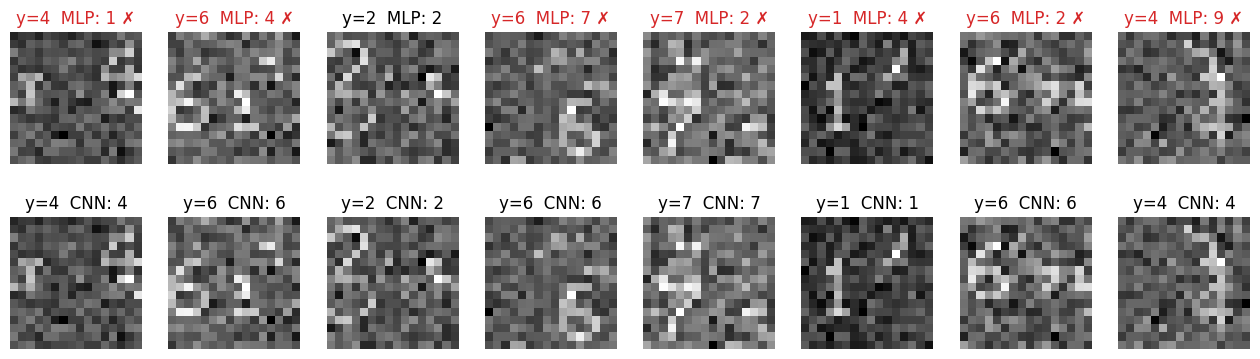

In [28]:
with torch.no_grad():
    preds = {"MLP": mlp_d(Xd_te[:8]).argmax(1), "CNN": cnn_big(Xd_te[:8]).argmax(1)}

fig, ax = plt.subplots(2, 8, figsize=(16, 4.4))
for row, (name, p) in enumerate(preds.items()):
    for k in range(8):
        ok = p[k] == Yd_te[k]
        ax[row, k].imshow(Xd_te[k, 0], cmap="gray"); ax[row, k].axis("off")
        ax[row, k].set_title(f"y={Yd_te[k].item()}  {name}: {p[k].item()}" + ("" if ok else " ✗"), color="k" if ok else "C3")
plt.show()

### 4.4 Scaling：MLP 和 CNN 各自做大

MLP 是不是只是还不够大？两种模型各做 4 个尺寸：MLP 的隐藏单元从 64 到 4096（4.2 用的是 256），CNN 的宽度 `w` 从 2 到 16。画出准确率随参数量的变化，实线是测试集，虚线是训练集。前面训过的两个直接复用，剩下 6 个在 CPU 上加起来大约 25 秒。

MLP 64    params    17,098  train 0.519  test 0.301
MLP 256   params    68,362  train 0.832  test 0.431
MLP 1024  params   273,418  train 0.983  test 0.496
MLP 4096  params 1,093,642  train 0.988  test 0.564
CNN 2     params     1,066  train 0.611  test 0.613
CNN 4     params     3,994  train 0.920  test 0.905
CNN 8     params    15,466  train 0.982  test 0.968
CNN 16    params    60,874  train 0.993  test 0.982


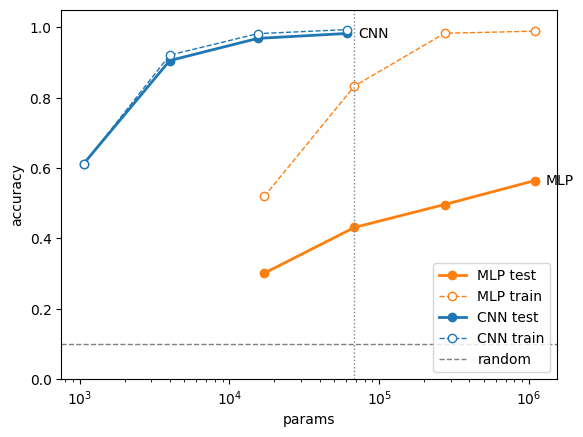

In [29]:
make = {"MLP": digit_mlp, "CNN": scaled_cnn}
sizes = {"MLP": [64, 256, 1024, 4096], "CNN": [2, 4, 8, 16]}   # MLP 的隐藏单元数 / CNN 的宽度 w
trained = {("MLP", 256): mlp_d, ("CNN", 16): cnn_big}          # 前面训过的直接用
curve = {"MLP": [], "CNN": []}                                 # 每个点：(参数量, 训练准确率, 测试准确率)
for kind in make:
    for s in sizes[kind]:
        if (kind, s) not in trained:
            torch.manual_seed(0)
            trained[kind, s] = fit(make[kind](s), mini_batch(Xd_tr, Yd_tr, 128), F.cross_entropy, steps=800, lr=3e-3)
        m = trained[kind, s]
        curve[kind].append((n_params(m), *report(f"{kind} {s}", m)))

for kind, color in [("MLP", "C1"), ("CNN", "C0")]:
    p, tr, te = zip(*curve[kind])
    plt.plot(p, te, "o-", color=color, lw=2, label=f"{kind} test")
    plt.plot(p, tr, "o--", color=color, lw=1, mfc="white", label=f"{kind} train")
    plt.annotate(kind, (p[-1], te[-1]), xytext=(8, 0), textcoords="offset points", va="center")
plt.axhline(0.1, ls="--", c="gray", lw=1, label="random")
plt.axvline(n_params(mlp_d), ls=":", c="gray", lw=1)           # 4.3 比较的那一档：4.2 的 MLP 的参数量
plt.xscale("log"); plt.xlabel("params"); plt.ylabel("accuracy"); plt.ylim(0, 1.05); plt.legend(loc="lower right"); plt.show()

两种模型的测试准确率（实线）都随参数量往上走，做大是有用的。但两者差距很大：

- **同样的参数，CNN 高得多**：竖的点线是 4.2 那个 MLP 的参数量（约 6.8 万），这一档 CNN 0.98，MLP 0.43。
- **MLP 加参数也追不上**：MLP 从 6.8 万加到 109 万参数，测试准确率只从 0.43 涨到 0.56。它的训练准确率（虚线）早就到了 0.99，多出来的参数大多拿去背训练集了。只有 4 千参数的 CNN（0.91）就远远超过它。
- **CNN 的训练线和测试线几乎重合**：学到的东西在没见过的图上同样成立。

先把结构选对（这里是“局部 + 平移不变”），再往大里加参数，参数才用得上。结构不对，加的参数大多拿去背训练集了，测试准确率涨得很慢。


### 4.5 数据 Scaling：数据量和标签噪声

4.4 固定 2 万张训练图，改的是模型大小。这里反过来：模型固定，改训练数据的量。

再加一个变量，**标签噪声**。和第 3 节一样，随机挑 30% 的训练图，把标签换成另外 9 类中的一个（模拟标注错误），测试集保持干净。两组数据是同一批图，只有标签不同。

为了省时间，这里用 4.4 里 `w=8` 的 CNN（约 1.5 万参数）。训练步数一律 800 步，数据少就多过几遍。训练集从 500 张到 2 万张，两组一共 12 次训练，CPU 上大约 2.5 分钟。

被翻错的标签比例 0.297
clean            N=   500  train 1.000  test 0.581
clean            N=  1000  train 1.000  test 0.726
clean            N=  2000  train 1.000  test 0.869
clean            N=  5000  train 0.991  test 0.922
clean            N= 10000  train 0.980  test 0.945
clean            N= 20000  train 0.982  test 0.968
30% label noise  N=   500  train 1.000  test 0.200
30% label noise  N=  1000  train 1.000  test 0.424
30% label noise  N=  2000  train 1.000  test 0.529
30% label noise  N=  5000  train 0.741  test 0.804
30% label noise  N= 10000  train 0.669  test 0.920
30% label noise  N= 20000  train 0.680  test 0.959


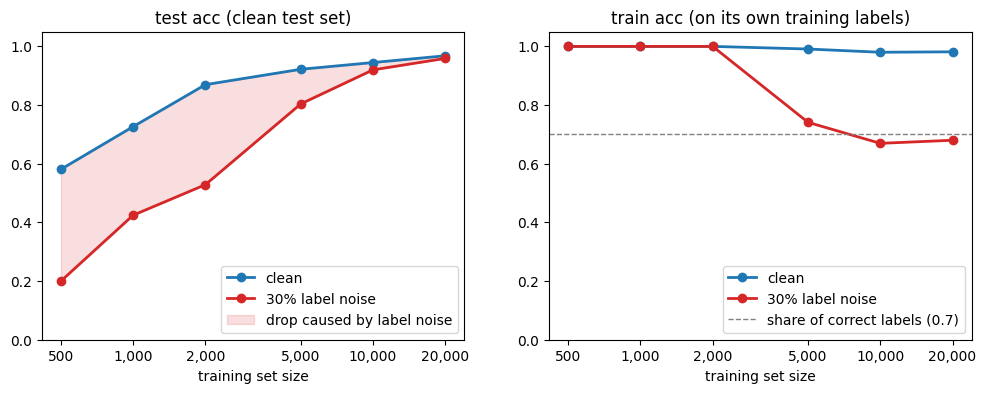

In [30]:
def flip_labels(Y, rate, seed=0):
    g = torch.Generator().manual_seed(seed)
    flip = torch.rand(len(Y), generator=g) < rate
    Y = Y.clone()
    Y[flip] = (Y[flip] + torch.randint(1, 10, (int(flip.sum()),), generator=g)) % 10    # 换成另外 9 类中随机一类
    return Y

Yd_noisy = flip_labels(Yd_tr, 0.3)
print(f"被翻错的标签比例 {(Yd_noisy != Yd_tr).float().mean():.3f}")

NS = [500, 1000, 2000, 5000, 10000, 20000]
data_curve = {"clean": [], "30% label noise": []}        # 每个点：(训练准确率（按它自己的训练标签算）, 干净测试集准确率)
for label, Y in [("clean", Yd_tr), ("30% label noise", Yd_noisy)]:
    for n in NS:
        torch.manual_seed(0)
        m = fit(scaled_cnn(8), mini_batch(Xd_tr[:n], Y[:n], 128), F.cross_entropy, steps=800, lr=3e-3)
        k = min(n, 2000)                                  # 训练准确率最多用 2000 张估计
        data_curve[label].append((acc(m, Xd_tr[:k], Y[:k]), acc(m, Xd_te, Yd_te)))
        print(f"{label:15s}  N={n:6d}  train {data_curve[label][-1][0]:.3f}  test {data_curve[label][-1][1]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for label, color in [("clean", "C0"), ("30% label noise", "C3")]:
    tr, te = zip(*data_curve[label])
    ax[0].plot(NS, te, "o-", color=color, lw=2, label=label)
    ax[1].plot(NS, tr, "o-", color=color, lw=2, label=label)
ax[0].fill_between(NS, [te for _, te in data_curve["30% label noise"]], [te for _, te in data_curve["clean"]],
                   color="C3", alpha=0.15, label="drop caused by label noise")
ax[1].axhline(0.7, ls="--", c="gray", lw=1, label="share of correct labels (0.7)")
for a, title in zip(ax, ["test acc (clean test set)", "train acc (on its own training labels)"]):
    a.set_xscale("log"); a.set_xticks(NS, [f"{n:,}" for n in NS]); a.minorticks_off(); a.set_xlabel("training set size"); a.set_ylim(0, 1.05); a.set_title(title); a.legend(loc="lower right")
plt.show()

**左图**：带噪那条线和干净那条线之间的阴影，就是标签噪声造成的损失。

- 数据少时损失很大：500 张时干净 0.58、带噪 0.20；2000 张时 0.87 对 0.53，差了 34 个点。
- 数据多时损失几乎消失：2 万张时 0.97 对 0.96，只差 1 个点。

**右图**说明了原因：

- 数据少时，带噪那组在自己训练标签上的准确率也是 1.00。模型把翻错的 30% 也一起背下来了，这些错误的对应关系混进模型里，测试准确率被拖下来一大截。
- 数据多时，这个数降到 0.68，接近训练集里标签正确的比例 0.7。也就是说，翻错的那些标签它基本不迎合，预测的是真实的数字。错标是随机的：每个数字的图里 70% 标对，剩下 30% 平摊到另外 9 类，每类只有 3% 左右。数据一多，正确的那一类在统计上占绝对多数，噪声就被平均掉了。

所以数据量本身就是对付标注噪声最直接的办法。第 3 节的 L2 / Dropout 是数据少时的补救；数据够多时，模型自己就不会去拟合噪声。

### 4.6 换个后端跑：CPU / MPS / CUDA

模型和数据一变大，计算量就跟着涨。同一份 PyTorch 代码可以跑在不同的硬件后端上：

- `cpu`：任何机器都有
- `cuda`：NVIDIA 显卡
- `mps`：Apple 芯片（M1 / M2 / M3…）里的 GPU

换后端只需要把模型和数据 `.to(device)`。先选后端：默认 `"auto"` 按 cuda → mps → cpu 的顺序挑一个能用的，也可以手动指定。后面的对比总会带上 CPU 作参照。前面各节都在 CPU 上跑，不受这里的选择影响。

In [31]:
import time

available = ["cpu"]
if torch.cuda.is_available():
    available.append("cuda")
if torch.backends.mps.is_available():
    available.append("mps")

BACKEND = "auto"                        # 可以改成 "cuda" / "mps" / "cpu"
if BACKEND == "auto":
    BACKEND = "cuda" if "cuda" in available else "mps" if "mps" in available else "cpu"
assert BACKEND in available, f"{BACKEND} 在这台机器上不可用，可用的后端：{available}"
backends = list(dict.fromkeys(["cpu", BACKEND]))          # 总是带上 CPU 作对照

def sync(dev):                          # GPU 是异步执行的：调用立刻返回，计时前要等它真正算完
    if dev.type == "cuda":
        torch.cuda.synchronize()
    elif dev.type == "mps":
        torch.mps.synchronize()

detail = {"cpu": f"{torch.get_num_threads()} 线程",
          "cuda": torch.cuda.get_device_name(0) if "cuda" in available else "",
          "mps": "Apple GPU"}
print(f"这台机器可用的后端：{available}")
print(f"选用：{BACKEND}（{detail[BACKEND]}），下面对比 {backends}")

这台机器可用的后端：['cpu', 'mps']
选用：mps（Apple GPU），下面对比 ['cpu', 'mps']


先看最纯粹的计算：两个 n×n 的矩阵相乘，一共 $2n^3$ 次浮点运算（$n^3$ 次乘法、$n^3$ 次加法）。除以耗时就是每秒浮点运算次数（FLOP/s），下面的单位是 GFLOP/s，即每秒十亿次。

In [32]:
def matmul_flops(dev, n):
    a, b = torch.randn(n, n, device=dev), torch.randn(n, n, device=dev)
    a @ b; sync(dev)                                          # 预热：第一次调用有初始化开销，不计时
    reps = max(3, min(1000, int(2e10 / (2 * n ** 3))))        # 小矩阵多算几次，计时才准
    t = time.perf_counter()
    for _ in range(reps):
        a @ b
    sync(dev)
    return 2 * n ** 3 * reps / (time.perf_counter() - t)

SIZES = [64, 256, 1024, 4096]
print("GFLOP/s " + "".join(f"{f'n={n}':>10s}" for n in SIZES))
for b in backends:
    print(f"{b:8s}" + "".join(f"{matmul_flops(torch.device(b), n) / 1e9:10,.0f}" for n in SIZES))

GFLOP/s       n=64     n=256    n=1024    n=4096
cpu             67     1,121     1,097     1,106
mps             14       745     2,311     2,601




矩阵乘法是理想情况。再看真实的训练：在每个后端上用 4.3 的大 CNN（`w=16`）从头训 800 步，设置和 4.3 一样。`FlopCounterMode` 能数出一步训练（前向 + 反向）里卷积和矩阵乘法的浮点运算量，乘上步数再除以耗时，就是训练时实际跑到的 FLOP/s。

In [33]:
from torch.utils.flop_counter import FlopCounterMode

def train_on(dev, steps=800, bs=128):
    torch.manual_seed(0)
    model = scaled_cnn(16).to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    X, Y = Xd_tr.to(dev), Yd_tr.to(dev)                     # 训练数据一次性搬到设备上，省得每步都拷贝
    def step():
        i = torch.randint(0, len(X), (bs,), device=dev)
        loss = F.cross_entropy(model(X[i]), Y[i])
        opt.zero_grad(); loss.backward(); opt.step()
    for _ in range(3):                                      # 预热，不计时
        step()
    sync(dev)
    t = time.perf_counter()
    for _ in range(steps):
        step()
    sync(dev)
    sec = time.perf_counter() - t
    model.eval()
    with torch.no_grad():
        test = (model(Xd_te.to(dev)).argmax(1) == Yd_te.to(dev)).float().mean().item()
    return sec, test

with FlopCounterMode(display=False) as counter:             # 数一步训练（batch 128，前向 + 反向）的浮点运算量
    F.cross_entropy(scaled_cnn(16)(Xd_tr[:128]), Yd_tr[:128]).backward()
step_flops = counter.get_total_flops()
print(f"每步 {step_flops / 1e9:.2f} GFLOP（只数卷积和矩阵乘法）\n")

for b in backends:
    sec, test = train_on(torch.device(b))
    print(f"{b:5s}  800 步 {sec:5.1f} s   {sec / 800 * 1e3:5.1f} ms/step   {step_flops * 800 / sec / 1e9:6.0f} GFLOP/s   test acc {test:.3f}")

每步 2.28 GFLOP（只数卷积和矩阵乘法）

cpu    800 步  25.4 s    31.7 ms/step       72 GFLOP/s   test acc 0.979
mps    800 步   5.0 s     6.2 ms/step      368 GFLOP/s   test acc 0.980


- **结果基本一样**：test acc 在 cpu 上是 0.979，在 mps 上是 0.980。不同硬件的浮点运算顺序不同，会有细微差别，但学到的是同一个东西。
- **速度差了约 5 倍**：cpu 22.0 秒，mps 4.4 秒。4.5 那种要训十几个模型的实验，用 GPU 能省很多时间。
- **实际跑到的 FLOP/s 远低于大矩阵乘法**：训练时 cpu 83、mps 411 GFLOP/s，对照上面 n=4096 的 1,119 和 2,461。这个 CNN 每一层都很小，batch 也只有 128，单次运算的规模远小于 4096×4096 的矩阵乘法，硬件吃不饱，就和上表里小矩阵的情况一样。

**可以试试**：把 `train_on` 的 `bs` 改成 1024（`steps` 相应减到 100），看看 GPU 的 FLOP/s 能涨多少，CPU 又会怎样。

---
## 5. RNN：需要记住过去

### 5.1 造数据

一批正弦序列 $x_t = \sin(\omega t + \varphi)$，每条的频率 $\omega$ 和相位 $\varphi$ 都随机。任务：看到 $x_1, \dots, x_t$，预测 $x_{t+1}$。

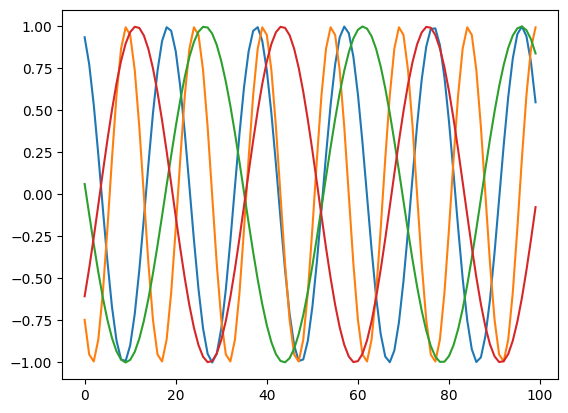

In [34]:
def make_waves(n, T, seed=None):
    g = torch.Generator().manual_seed(seed) if seed is not None else None
    w = 0.15 + 0.35 * torch.rand(n, 1, generator=g)
    phi = 2 * math.pi * torch.rand(n, 1, generator=g)
    return torch.sin(w * torch.arange(T).float() + phi)      # (n, T)

waves = make_waves(4, 100, seed=0)
for i in range(4): plt.plot(waves[i])
plt.show()

### 5.2 只看当前一个点不够

先试最简单的：MLP 输入 $x_t$，输出 $x_{t+1}$。

问题是当前值 0.5 时，曲线可能在上升也可能在下降，频率也不知道。光凭一个点，下一个点是不确定的。单步预测还勉强能凑合（下一个点总在当前点附近），让它从第 30 个点开始自己往下写就彻底露馅了。

step     0  loss 0.5432
step   500  loss 0.0506
step  1000  loss 0.0508


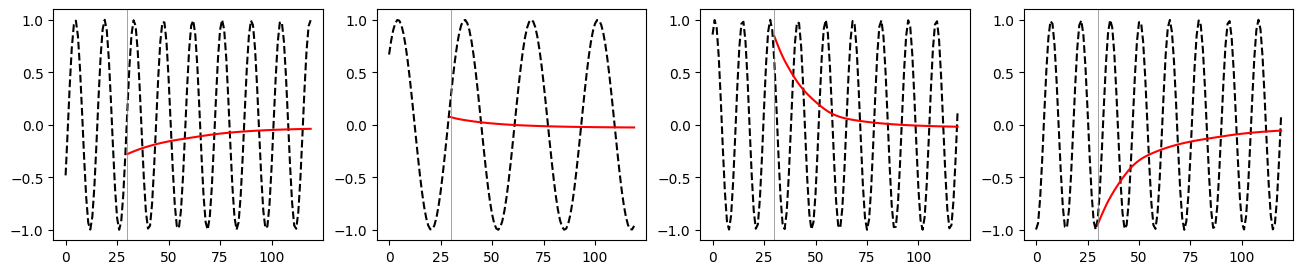

In [35]:
def wave_batch(n=64, T=50):
    def get():
        s = make_waves(n, T)
        return s[:, :-1].reshape(-1, 1), s[:, 1:].reshape(-1, 1)
    return get

torch.manual_seed(0)
mlp_seq = fit(nn.Sequential(nn.Linear(1, 64), nn.ReLU(), nn.Linear(64, 1)), wave_batch(), F.mse_loss, steps=1500, lr=3e-3, log_every=500)

test = make_waves(4, 120, seed=5)
with torch.no_grad():
    cur, gen = test[:, 29:30], []
    for _ in range(90):
        cur = mlp_seq(cur)                 # 用自己的预测作为下一步的输入
        gen.append(cur)
    gen = torch.cat(gen, 1)

fig, ax = plt.subplots(1, 4, figsize=(16, 3))
for i in range(4):
    ax[i].plot(test[i], "k--"); ax[i].plot(range(30, 120), gen[i], "r"); ax[i].axvline(30, c="gray", lw=0.5)
plt.show()

曲线迅速塌到 0：对一个不知道方向和频率的模型，“猜平均值”是它能做的最好选择。

### 5.3 带一个记忆往前走

需要一个东西把过去的信息累积起来。引入一个**隐藏状态** $h_t$，每读一个新输入就更新一次：

$$h_t = \tanh(W_x x_t + W_h h_{t-1} + b), \qquad \hat x_{t+1} = W_o h_t$$

$h_t$ 是对 $x_1, \dots, x_t$ 的总结。注意每一步用的都是同一组 $W_x, W_h$：CNN 在空间上共享权重，RNN 在时间上共享权重。

下面手写这个循环。

In [36]:
class MyRNN(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.hidden = hidden
        self.Wx = nn.Linear(1, hidden)
        self.Wh = nn.Linear(hidden, hidden, bias=False)
        self.out = nn.Linear(hidden, 1)

    def forward(self, x, h=None):              # x: (batch, T)
        if h is None:
            h = torch.zeros(x.shape[0], self.hidden)
        preds = []
        for t in range(x.shape[1]):
            h = torch.tanh(self.Wx(x[:, t:t + 1]) + self.Wh(h))
            preds.append(self.out(h))
        self.h = h                             # 留着最后的状态，生成时接着用
        return torch.cat(preds, 1)             # (batch, T)

def seq_batch(n=64, T=50):
    def get():
        s = make_waves(n, T)
        return s[:, :-1], s[:, 1:]             # 输入 x_1..x_{T-1}，目标 x_2..x_T
    return get

torch.manual_seed(0)
rnn = fit(MyRNN(), seq_batch(), F.mse_loss, steps=1500, lr=3e-3, log_every=500)

step     0  loss 0.5012
step   500  loss 0.0025
step  1000  loss 0.0015


### 5.4 让它自己往下写

和 5.2 同样的测试：给 30 个点作为开头，之后每一步都把自己的预测当作下一个输入，连续生成 90 步。模型必须从开头 30 个点里推断出频率和相位，存在 $h$ 里。

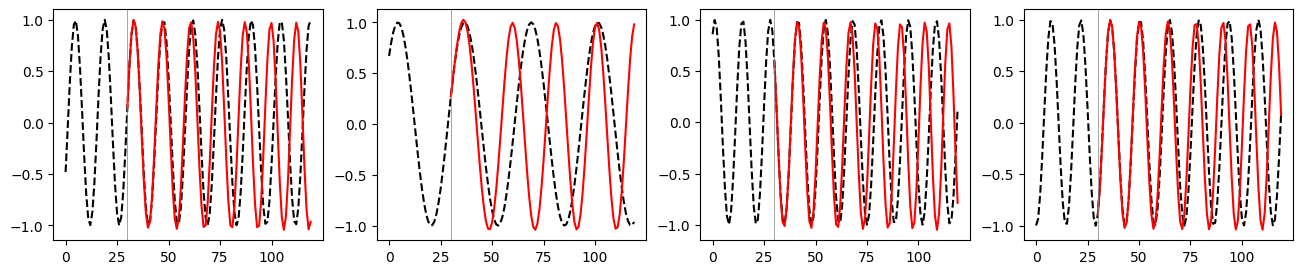

In [37]:
with torch.no_grad():
    pred = rnn(test[:, :30])
    h, cur = rnn.h, pred[:, -1:]
    gen = [cur]
    for _ in range(89):
        cur = rnn(cur, h); h = rnn.h
        gen.append(cur)
    gen = torch.cat(gen, 1)

fig, ax = plt.subplots(1, 4, figsize=(16, 3))
for i in range(4):
    ax[i].plot(test[i], "k--"); ax[i].plot(range(30, 120), gen[i], "r")
    ax[i].axvline(30, c="gray", lw=0.5)
plt.show()

“读一段，预测下一个，再把预测喂回去接着写”，就是后来 GPT 生成文本的方式，只是序列从数值换成了词。

实际使用时用 `nn.RNN`，或者加了门控、更容易训练的 `nn.GRU` / `nn.LSTM`，接口相同，下一节用 `nn.GRU`。

---
## 6. Attention / Transformer：按内容去找

### 6.1 RNN 的瓶颈

RNN 把过去的一切压缩进一个固定大小的 $h$。如果任务需要精确地回忆很多条信息，这个瓶颈就会暴露。

造一个“查字典”任务（associative recall）：序列由若干个 (key, value) 对组成，最后给出一个 key，要求回答它对应的 value。

```
(k7, v2) (k19, v5) (k3, v0) (k11, v6)   query: k3   →  答案 v0
```

每个位置编码成一个向量：key 的 one-hot 拼上 value 的 one-hot；最后的 query 位置只有 key，外加一个“我是问题”的标记位。

torch.Size([1, 5, 41])


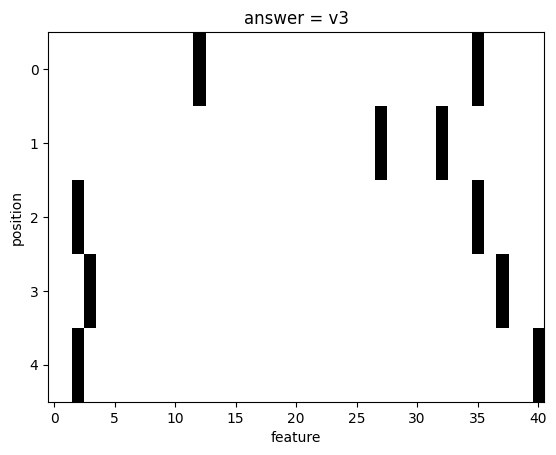

In [38]:
NK, NV = 32, 8                     # 32 种 key，8 种 value

def make_recall(n, pairs, seed=None):
    g = torch.Generator().manual_seed(seed) if seed is not None else None
    keys = torch.argsort(torch.rand(n, NK, generator=g), 1)[:, :pairs]   # 每条序列内 key 互不相同
    vals = torch.randint(0, NV, (n, pairs), generator=g)
    q = torch.randint(0, pairs, (n,), generator=g)                       # 问第几个
    idx = torch.arange(n)

    X = torch.zeros(n, pairs + 1, NK + NV + 1)
    X[:, :pairs].scatter_(2, keys.unsqueeze(2), 1.0)                     # key one-hot
    X[:, :pairs].scatter_(2, (NK + vals).unsqueeze(2), 1.0)              # value one-hot
    X[idx, pairs, keys[idx, q]] = 1.0                                    # query 的 key
    X[:, pairs, -1] = 1.0                                                # “我是问题”
    return X, vals[idx, q]

X, Y = make_recall(1, 4, seed=0)
print(X.shape)        # (1, 5, 41)：4 个 pair + 1 个 query
plt.imshow(X[0], cmap="gray_r", aspect="auto"); plt.xlabel("feature"); plt.ylabel("position"); plt.title(f"answer = v{Y.item()}"); plt.show()

In [39]:
class GRUReader(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.gru = nn.GRU(NK + NV + 1, hidden, batch_first=True)
        self.out = nn.Linear(hidden, NV)
    def forward(self, x):
        _, h = self.gru(x)               # h: 读完整条序列后的最终状态
        return self.out(h[-1])

def recall_batch(pairs, n=128):
    return lambda: make_recall(n, pairs)

PAIRS = [1, 2, 4, 8]
gru_acc = []
for P in PAIRS:
    torch.manual_seed(0)
    m = fit(GRUReader(), recall_batch(P), F.cross_entropy, steps=3000, lr=3e-3)
    Xt, Yt = make_recall(2000, P, seed=123)
    gru_acc.append(acc(m, Xt, Yt))
    print(f"pairs={P}  GRU acc {gru_acc[-1]:.3f}   (random guess {1 / NV:.3f})")

pairs=1  GRU acc 1.000   (random guess 0.125)
pairs=2  GRU acc 0.783   (random guess 0.125)
pairs=4  GRU acc 0.416   (random guess 0.125)
pairs=8  GRU acc 0.315   (random guess 0.125)


一两对还能记住，对数一多准确率就明显掉下去（同样的训练步数下）。

### 6.2 换个思路：回头去找

人做这个任务时不会把所有 pair 背下来，而是拿着问题里的 key **回头扫一遍**，找到 key 相同的那一项，读出它的 value。

把这个过程写成可微分的运算：

1. 每个位置生成一个 **key 向量** $k_j$（“我这里有什么”）和一个 **value 向量** $v_j$（“如果你找到我，拿走什么”）
2. 提问的位置生成一个 **query 向量** $q$（“我在找什么”）
3. 用点积 $q \cdot k_j$ 衡量匹配程度，softmax 变成权重 $a_j$，所有权重加起来是 1
4. 输出 $\sum_j a_j v_j$：匹配上的位置贡献最大

所有位置一起算，写成矩阵就是

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt d}\right) V$$

$\sqrt d$ 用来防止点积太大导致 softmax 过于尖锐、梯度消失。


设 $q, k \in \mathbb{R}^d$ 各分量独立、均值 0、方差 1，则内积

$$q \cdot k = \sum_{i=1}^{d} q_i k_i$$

每项 $q_i k_i$ 均值 0、方差 $\text{Var}(q_i k_i) = \text{Var}(q_i)\text{Var}(k_i) = 1$（独立零均值），因此

$$\text{Var}(q \cdot k) = d$$

即 $q \cdot k$ 的标准差为 $\sqrt{d}$。$d$ 越大，内积值越可能出现大绝对值。

除以 $\sqrt{d}$ 后

$$\text{Var}\!\left(\frac{q \cdot k}{\sqrt{d}}\right) = \frac{d}{d} = 1$$

内积的方差恢复为 1，不随 $d$ 增长，softmax 保持在梯度有效的区间。

一句话：**除以 $\sqrt{d}$ 是对内积做方差归一化，防止 softmax 饱和导致梯度消失。**

In [40]:
class SelfAttention(nn.Module):
    def __init__(self, d_in, d=32):
        super().__init__()
        self.q = nn.Linear(d_in, d)
        self.k = nn.Linear(d_in, d)
        self.v = nn.Linear(d_in, d)
    def forward(self, x):                                      # x: (batch, L, d_in)
        Q, K, V = self.q(x), self.k(x), self.v(x)              # 各 (batch, L, d)
        scores = Q @ K.transpose(1, 2) / math.sqrt(Q.shape[-1])  # (batch, L, L)：每对位置的匹配分数
        self.A = scores.softmax(-1)                            # 存下来画图
        return self.A @ V                                      # (batch, L, d)

class AttnReader(nn.Module):
    def __init__(self, d=32):
        super().__init__()
        self.attn = SelfAttention(NK + NV + 1, d)
        self.out = nn.Linear(d, NV)
    def forward(self, x):
        return self.out(self.attn(x)[:, -1])                   # 取最后一个位置（query）的输出

attn_acc, attn_models = [], {}
for P in PAIRS:
    torch.manual_seed(0)
    m = fit(AttnReader(), recall_batch(P), F.cross_entropy, steps=1500, lr=3e-3)
    Xt, Yt = make_recall(2000, P, seed=123)
    attn_acc.append(acc(m, Xt, Yt)); attn_models[P] = m
    print(f"pairs={P}  Attention acc {attn_acc[-1]:.3f}")

pairs=1  Attention acc 1.000
pairs=2  Attention acc 1.000
pairs=4  Attention acc 1.000
pairs=8  Attention acc 1.000


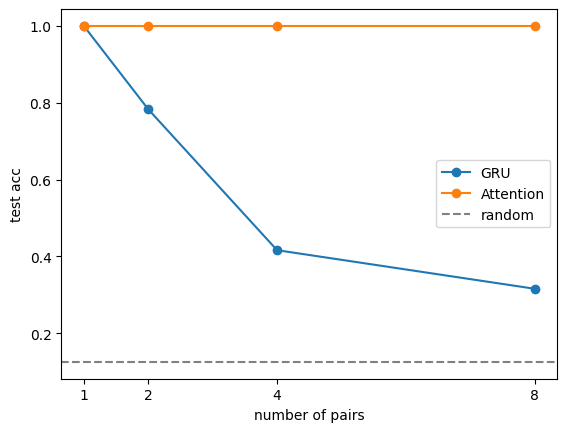

In [41]:
plt.plot(PAIRS, gru_acc, "o-", label="GRU")
plt.plot(PAIRS, attn_acc, "o-", label="Attention")
plt.axhline(1 / NV, ls="--", c="gray", label="random")
plt.xlabel("number of pairs"); plt.ylabel("test acc"); plt.xticks(PAIRS); plt.legend(); plt.show()

### 6.3 看它在看哪里

画出 query 位置对每个 pair 的注意力权重，也就是 $A$ 的最后一行。

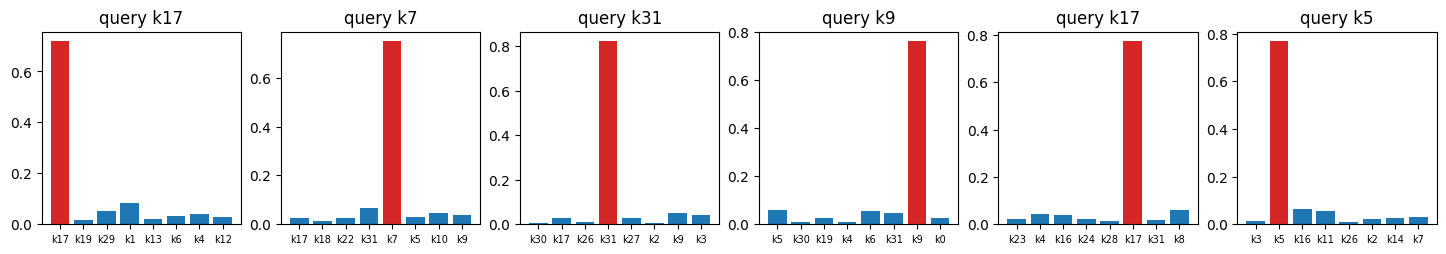

In [42]:
P = 8
m = attn_models[P]
Xs, Ys = make_recall(6, P, seed=7)
with torch.no_grad():
    m(Xs)
A = m.attn.A[:, -1, :P]                                          # query 对 8 个 pair 的权重
keys_in_seq = Xs[:, :P, :NK].argmax(-1)
query_key = Xs[:, P, :NK].argmax(-1)

fig, ax = plt.subplots(1, 6, figsize=(18, 2.5))
for i in range(6):
    ax[i].bar(range(P), A[i], color=["C3" if k == query_key[i] else "C0" for k in keys_in_seq[i]])
    ax[i].set_xticks(range(P)); ax[i].set_xticklabels([f"k{k}" for k in keys_in_seq[i].tolist()], fontsize=7)
    ax[i].set_title(f"query k{query_key[i].item()}")
plt.show()

红色柱子是 key 和问题匹配的那个 pair，注意力几乎全压在它上面。模型自己学会了“拿着问题去找相同的 key”。

RNN 只能单向往前读，信息必须一路靠 $h$ 传过去；attention 让任意两个位置之间直接连通，序列再长，找东西的距离都是一步。

**一个要注意的地方**：上面的计算对位置的顺序完全不敏感，把 8 个 pair 打乱，结果不变。这个任务恰好不在乎顺序，所以没出问题。但语言是在乎顺序的，所以真正的 Transformer 会给每个位置加上一个**位置编码**，把“第几个”这个信息加进输入向量里。

### 6.4 从这一个 attention 到 GPT

一个完整的 Transformer block 是：attention（多个头并行）→ 一个 MLP，每一步外面套残差连接和 LayerNorm。把 block 叠几十层就是 Transformer。

GPT：

- 输入是词，用 embedding 变成向量，再加位置编码
- 每个位置只能看它前面的位置（causal mask），训练任务就是第 5 节的“预测下一个”，生成方式也是第 5 节的“把预测喂回去接着写”

也就是说：**GPT = 第 6 节的结构 + 第 5 节的任务。**